## Week1 Assignment  

#### Objectives:
- Explore the basic structure and functionality of the R programming environment.​
- Load and explore datasets in R using foundational commands.

#### Instructions
1. Dataset Preparation:

    - Download the provided dataset:
        customer_data_week1_updated.csv  
    - Load the dataset into R.  
    - Display the first few rows and check its structure.

2. Descriptive Summary:

    - Generate summary statistics for the dataset.  
    - Identify variables in the dataset that represent:  
        - Categorical data.  
        - Numeric data.  

3. Basic Data Visualization:

    - Create a bar chart for a categorical variable (e.g., Customer_Segment).
    - Create a histogram for a numeric variable (e.g., Age).

4. Reflection: Write a short reflection (150–200 words) addressing the following:

    - What patterns or trends do you observe in the data?  
    - Were there any surprising results or unusual distributions?  
    - How might the variables in this dataset be useful for data mining?  
    - Deliverables, in 1 PDF combine:  
        - A well-commented R script containing all code used for the activity.
        - A reflection summarizing your observations and insights.

### 1. Dataset preparation

In [1]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# read dataset file
fname =  Path("../datasets/customer_data_week1_updated.csv")

customer_data = pd.read_csv(fname)

customer_data.head()

,CustomerID,Age,Gender,AnnualIncome,MembershipYears,TotalPurchases,LastPurchaseAmount,Customer_Segment
0,1001,63,Female,98929,1,48,149.68,Standard
1,1002,20,Male,79606,4,21,193.00,New
2,1003,46,Female,48275,2,10,121.11,VIP
3,1004,52,Male,33026,4,9,222.18,New
4,1005,56,Male,85718,1,1,124.66,Standard


### 2. Descriptive Summary

#### 2.1 Summary Statistics

In [2]:
# inspect the dataset
display(customer_data.describe(include="all"))

,CustomerID,Age,Gender,AnnualIncome,MembershipYears,TotalPurchases,LastPurchaseAmount,Customer_Segment
count,100.000000,100.000000,100,100.000000,100.000000,100.000000,100.000000,100
unique,NaN,NaN,3,NaN,NaN,NaN,NaN,4
top,NaN,NaN,Male,NaN,NaN,NaN,NaN,Standard
freq,NaN,NaN,52,NaN,NaN,NaN,NaN,45
mean,1050.500000,44.380000,NaN,75395.300000,4.840000,25.770000,245.015500,NaN
std,29.011492,15.396956,NaN,25816.126982,2.751382,13.747988,143.166823,NaN
min,1001.000000,18.000000,NaN,30604.000000,1.000000,1.000000,26.320000,NaN
25%,1025.750000,31.750000,NaN,53587.250000,2.750000,15.750000,133.922500,NaN
50%,1050.500000,45.000000,NaN,73340.000000,4.000000,24.500000,216.545000,NaN
75%,1075.250000,57.250000,NaN,94401.750000,8.000000,38.000000,359.692500,NaN


#### 2.2 Categorical and numerical 

Columns: ['CustomerID', 'Age', 'Gender', 'AnnualIncome', 'MembershipYears',
       'TotalPurchases', 'LastPurchaseAmount', 'Customer_Segment']

Numerical: Age, AnnualIncome, MembershipYears, TotalPurchases, LastPurchaseAmount  

Categorical: Gender, Customer_Segment  

Identifier: CustomerID

In [3]:

display(customer_data.columns)

display(customer_data.dtypes)

#inspect 'Customer_Segment', a categorical variable
display(customer_data["Customer_Segment"].unique())
display(customer_data["Customer_Segment"].value_counts())

Index(['CustomerID', 'Age', 'Gender', 'AnnualIncome', 'MembershipYears',
       'TotalPurchases', 'LastPurchaseAmount', 'Customer_Segment'],
      dtype='str')

CustomerID              int64
Age                     int64
Gender                    str
AnnualIncome            int64
MembershipYears         int64
TotalPurchases          int64
LastPurchaseAmount    float64
Customer_Segment          str
dtype: object

<StringArray>
['Standard', 'New', 'VIP', 'Premium']
Length: 4, dtype: str

Customer_Segment
Standard    45
Premium     28
VIP         18
New          9
Name: count, dtype: int64

### 3. Basic Data Visualization:

#### check for missing data
result: no data is missing

In [4]:
# inspect missing data
# missing values in each column
customer_data.isna().sum()
# total count of missing values
customer_data.isna().sum().sum()
#rows with at least one missing value
customer_data[customer_data.isna().any(axis=1)]

# customer_data.isna().mean().mul(100).round(1)

,CustomerID,Age,Gender,AnnualIncome,MembershipYears,TotalPurchases,LastPurchaseAmount,Customer_Segment


#### 3.1 Bar chart for Categorical Variable
varible: Customer_Segment

,Count,Percentage
Customer_Segment,,
Standard,45,45.0%
Premium,28,28.0%
VIP,18,18.0%
New,9,9.0%


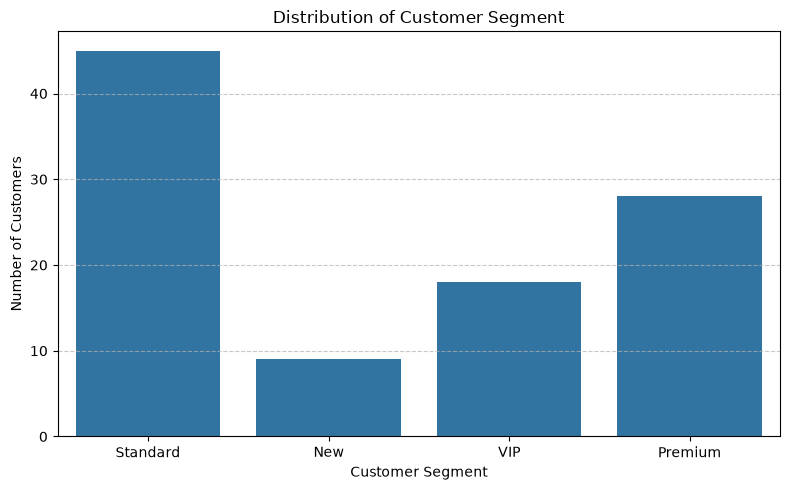

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=customer_data, x="Customer_Segment", ax=ax)
ax.set(
    title="Distribution of Customer Segment",
    xlabel="Customer Segment",
    ylabel="Number of Customers"
)
ax.grid(True, axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

customer_segment_counts = customer_data["Customer_Segment"].value_counts()

summary = pd.DataFrame({
    "Count": customer_segment_counts,
    "Percentage": customer_segment_counts.div(customer_segment_counts.sum()).mul(100).round(1).map(lambda val:f"{val:.1f}%")
})

display(summary)

#### 3.2 Histogram of Numeric variable
variable: AnnualIncome

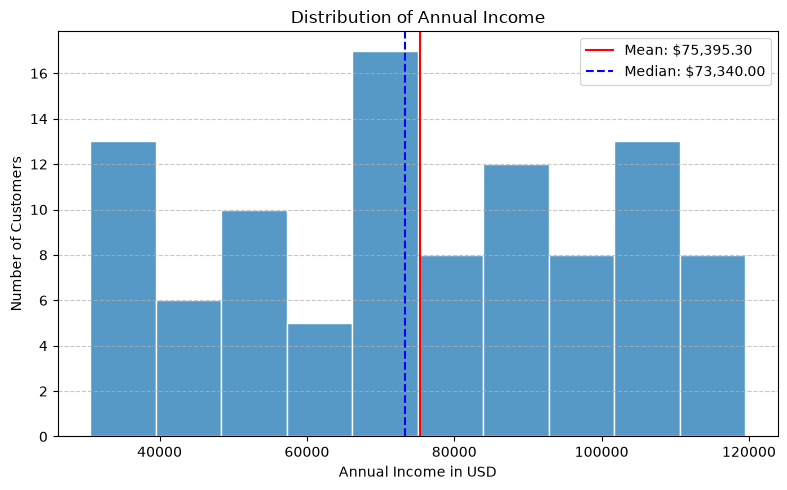

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax = sns.histplot(data=customer_data, x="AnnualIncome", bins=10, stat="count", edgecolor="white", ax = ax)
ax.set(
    title="Distribution of Annual Income",
    xlabel="Annual Income in USD",
    ylabel="Number of Customers"
)

ax.grid(visible=True, axis="y", linestyle="--", alpha=0.7)

mean_income = customer_data["AnnualIncome"].mean()
median_income = customer_data["AnnualIncome"].median()

plt.axvline(x=mean_income, linestyle="-", color="red", label=f"Mean: ${mean_income:,.2f}")
plt.axvline(x=median_income, linestyle="--", color="blue", label=f"Median: ${median_income:,.2f}")

plt.legend()

plt.tight_layout()

#### Annual income by customer segment

In [7]:
seg_income=customer_data.groupby("Customer_Segment")["AnnualIncome"].agg(
    func=["count", "mean", "median"]
).round(0)


seg_age=customer_data.groupby("Customer_Segment")["Age"].agg(
    func=["count", "mean", "median"]
).round(0)

display(seg_income)
display(seg_age)

,count,mean,median
Customer_Segment,,,
New,9,81975.0,90144.0
Premium,28,74676.0,72400.0
Standard,45,74906.0,72970.0
VIP,18,74446.0,72437.0


,count,mean,median
Customer_Segment,,,
New,9,46.0,46.0
Premium,28,41.0,40.0
Standard,45,45.0,48.0
VIP,18,46.0,48.0


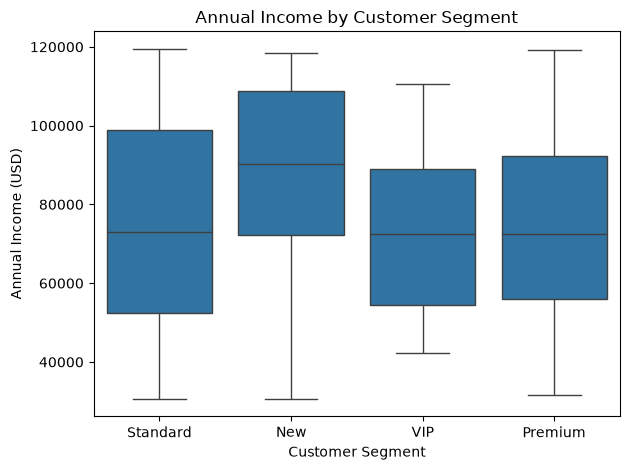

In [8]:
sns.boxplot(data=customer_data, x="Customer_Segment", y="AnnualIncome")
plt.title("Annual Income by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Annual Income (USD)")
plt.tight_layout()

### 4. Reflection

The dataset contains 100 customers and 8 variables describing their demographics, income, purchasing behaviour and customer segments. The variables include numerical measurements, namely, age, annual income, membership years and total purchases, as well as categorical variables, namely, gender, and customer segment. No missing values were identified.  

The customer segment distribution shows the standard customer represent the largest group, accounting for 45% of the sample, followed by premium customers at 28%, VIP at 18% and new customers at 9%.  

Annual income ranges approximately between 30.6k and 119.5k USD, with a mean income of 75.4k and median of 73.3k. An interesting observation is that the new customers have a higher average income of approximately 81.9k compared with other segments whose average incomes are relatively similar. However, the new segment contains only nine customers.   

These variables could be useful for data mining since they provide information about customer characteristics and purchasing behaviour. Regression could be used to predict purchasing amounts, while clustering could help identify groups of customers with similar characteristics. Predictive classification could use variables like age, annual income, and total purchases to predict a customer's likelihood of upgrading from standard to the VIP segment. These analyses could support customer profiling and more informed business decisions.